# MicroGrad Demo — Assignment 1
**Abdelmoneim Mahmoud — 23P0015** — CSE485/CSE488 Deep Learning

This notebook uses the scalar autograd engine (`src/engine.py`) and the MLP API (`src/nn.py`) to:
1. check the gradients against finite differences,
2. train a small MLP on the two-moons dataset,
3. plot the training curves and the decision boundary.

In [1]:
import sys, random
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from src.engine import Value
from src.nn import MLP

sys.setrecursionlimit(10000)  # the total loss graph is a few hundred nodes deep
random.seed(1337)            # nn.py uses Python's random
np.random.seed(1337)

## 1. Gradient check
We compare the gradients from `backward()` with central finite differences $\frac{f(x+h)-f(x-h)}{2h}$ on a function that uses every operator.

In [2]:
def f(a, b):
    return ((a * b + b ** 3) / (a - 4.0)).tanh() + (a * 0.5).exp() - 2.0 / b

a, b = Value(1.5), Value(-0.7)
out = f(a, b)
out.backward()

h = 1e-6
F = lambda x, z: f(Value(x), Value(z)).data
num_a = (F(1.5 + h, -0.7) - F(1.5 - h, -0.7)) / (2 * h)
num_b = (F(1.5, -0.7 + h) - F(1.5, -0.7 - h)) / (2 * h)
print(f'df/da  autograd = {a.grad:.6f}   numerical = {num_a:.6f}')
print(f'df/db  autograd = {b.grad:.6f}   numerical = {num_b:.6f}')
assert abs(a.grad - num_a) < 1e-5 and abs(b.grad - num_b) < 1e-5

df/da  autograd = 1.432677   numerical = 1.432677
df/db  autograd = 3.197680   numerical = 3.197680


## 2. Data
100 points from `make_moons`. Labels are mapped to $\{-1, +1\}$ and everything is converted to plain Python floats, because the engine only accepts `int`/`float`, not NumPy scalars.

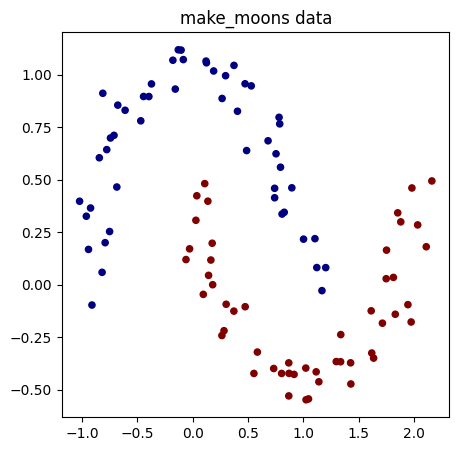

In [3]:
X_np, y_np = make_moons(n_samples=100, noise=0.1, random_state=1337)
X = [[float(v) for v in row] for row in X_np]
y = [float(2 * t - 1) for t in y_np]

plt.figure(figsize=(5, 5))
plt.scatter(X_np[:, 0], X_np[:, 1], c=y_np, s=20, cmap='jet')
plt.title('make_moons data'); plt.show()

## 3. Model and loss
`MLP(2, [16, 16, 1])`: two tanh hidden layers and a linear output (337 parameters).

Loss = mean SVM hinge loss $\max(0, 1 - y_i\,s_i)$ + L2 regularisation $\alpha\sum p^2$. `max(0, z)` is written as `z * (z.data > 0)`, so the gradient is 1 for a violated margin and 0 otherwise.

In [4]:
model = MLP(2, [16, 16, 1])
print('number of parameters:', len(model.parameters()))

def loss_fn():
    scores = [model(x) for x in X]
    hinge = [(1 - yi * si) * float((1 - yi * si).data > 0) for yi, si in zip(y, scores)]
    data_loss = sum(hinge) * (1.0 / len(hinge))
    alpha = 1e-4
    reg_loss = alpha * sum(p * p for p in model.parameters())
    acc = sum((yi > 0) == (si.data > 0) for yi, si in zip(y, scores)) / len(y)
    return data_loss + reg_loss, acc

number of parameters: 337


## 4. Training (SGD)
Each step: forward pass → `zero_grad()` → `backward()` → parameter update. The learning rate decays linearly from 1.0 to 0.1.

In [5]:
steps = 100
losses, accs = [], []
for k in range(steps):
    loss, acc = loss_fn()
    model.zero_grad()
    loss.backward()
    lr = 1.0 - 0.9 * k / steps
    for p in model.parameters():
        p.data -= lr * p.grad
    losses.append(loss.data); accs.append(acc)
    if k % 10 == 0 or k == steps - 1:
        print(f'step {k:3d}  loss {loss.data:.4f}  accuracy {acc*100:.0f}%')

step   0  loss 0.8660  accuracy 68%


step  10  loss 0.2279  accuracy 91%


step  20  loss 0.2400  accuracy 90%


step  30  loss 0.0738  accuracy 100%


step  40  loss 0.0372  accuracy 100%


...

step  60  loss 0.0175  accuracy 100%


step  70  loss 0.0173  accuracy 100%


step  80  loss 0.0156  accuracy 100%


step  90  loss 0.0147  accuracy 100%


step  99  loss 0.0144  accuracy 100%


## 5. Results

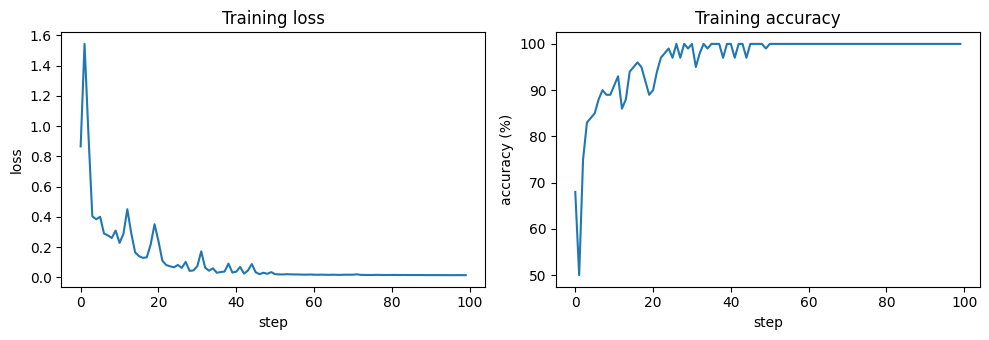

In [6]:
import os
os.makedirs('report/figures', exist_ok=True)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(losses); ax[0].set_xlabel('step'); ax[0].set_ylabel('loss'); ax[0].set_title('Training loss')
ax[1].plot([a * 100 for a in accs]); ax[1].set_xlabel('step'); ax[1].set_ylabel('accuracy (%)')
ax[1].set_title('Training accuracy')
plt.tight_layout(); plt.savefig('report/figures/curves.png', dpi=150); plt.show()

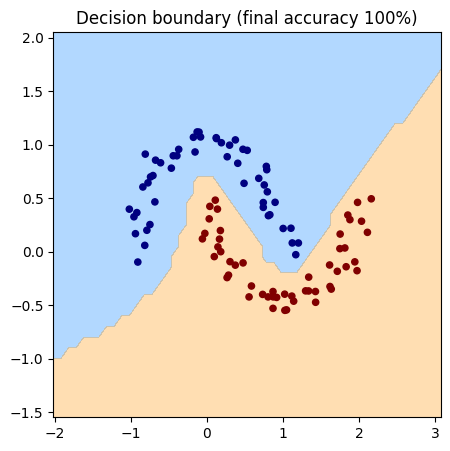

In [7]:
h = 0.1
x_min, x_max = X_np[:, 0].min() - 1, X_np[:, 0].max() + 1
y_min, y_max = X_np[:, 1].min() - 1, X_np[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
grid = [[float(a), float(b)] for a, b in zip(xx.ravel(), yy.ravel())]
Z = np.array([model(p).data > 0 for p in grid]).reshape(xx.shape)

plt.figure(figsize=(5, 5))
plt.contourf(xx, yy, Z, cmap='jet', alpha=0.3)
plt.scatter(X_np[:, 0], X_np[:, 1], c=y_np, s=20, cmap='jet')
plt.title(f'Decision boundary (final accuracy {accs[-1]*100:.0f}%)')
plt.savefig('report/figures/boundary.png', dpi=150, bbox_inches='tight'); plt.show()

The network separates the two moons. The loss falls steadily, and training accuracy reaches the value printed above.